# Load the dataset

In [70]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [71]:
df = pd.read_csv('credit_risk_dataset.csv')

In [72]:
df.head()

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


# Exploratory Data Analysis (EDA)

In [73]:
df.shape

(32581, 12)

In [74]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  object 
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  object 
 5   loan_grade                  32581 non-null  object 
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  object 
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), object(4)
memory usage: 3.0+ MB
None


In [75]:
df.isnull().sum()

person_age                       0
person_income                    0
person_home_ownership            0
person_emp_length              895
loan_intent                      0
loan_grade                       0
loan_amnt                        0
loan_int_rate                 3116
loan_status                      0
loan_percent_income              0
cb_person_default_on_file        0
cb_person_cred_hist_length       0
dtype: int64

In [76]:
df['loan_status'].unique()

array([1, 0])

In [77]:
df['loan_status'].value_counts()

loan_status
0    25473
1     7108
Name: count, dtype: int64

<Axes: xlabel='loan_status', ylabel='count'>

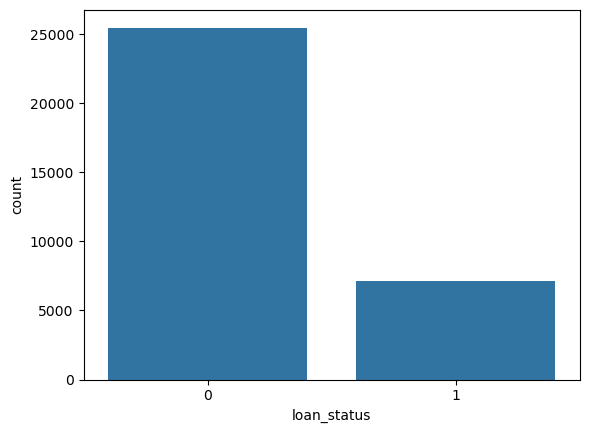

In [78]:
sns.countplot(x = 'loan_status', data = df)

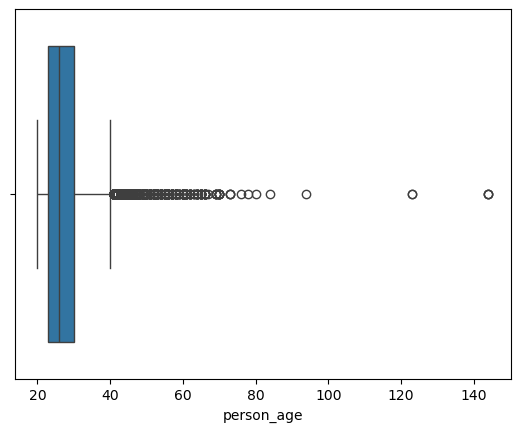

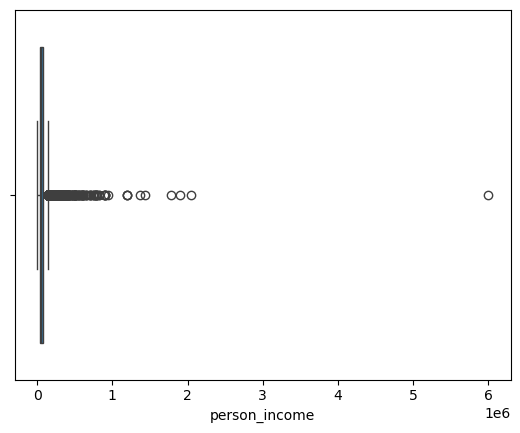

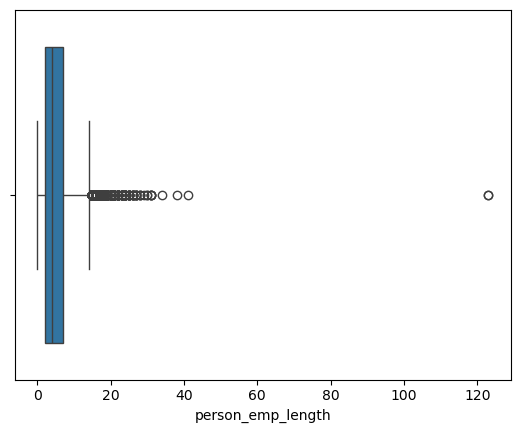

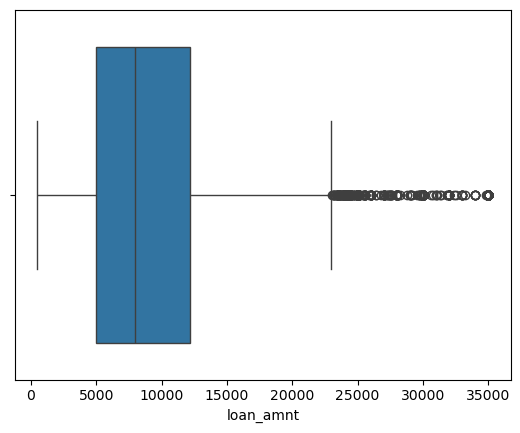

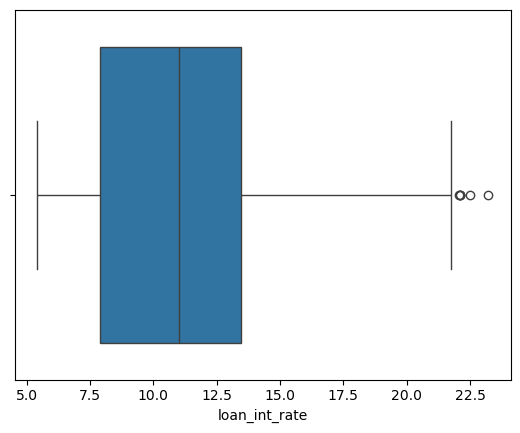

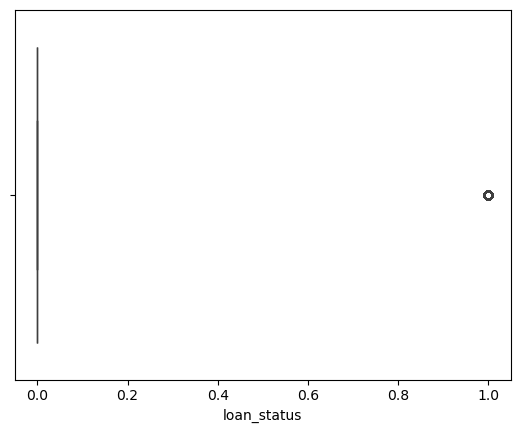

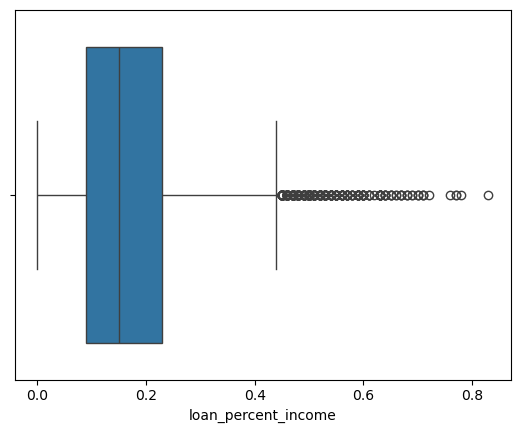

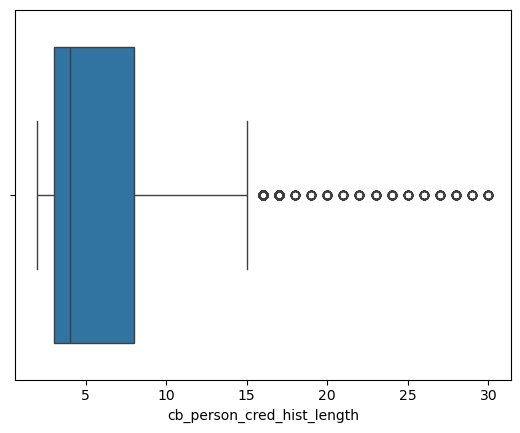

In [79]:
numerical_cols = df.select_dtypes(include = np.number)
for i in numerical_cols:
    sns.boxplot(x = df[i])
    plt.show()

In [80]:
(df['person_age'] > 100).sum()

np.int64(5)

In [81]:
(df['person_emp_length'] > 60).sum()

np.int64(2)

In [82]:
df.describe()

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,32581.000000,3.258100e+04,31686.000000,32581.000000,29465.000000,32581.000000,32581.000000,32581.000000
mean,27.734600,6.607485e+04,4.789686,9589.371106,11.011695,0.218164,0.170203,5.804211
std,6.348078,6.198312e+04,4.142630,6322.086646,3.240459,0.413006,0.106782,4.055001
min,20.000000,4.000000e+03,0.000000,500.000000,5.420000,0.000000,0.000000,2.000000
25%,23.000000,3.850000e+04,2.000000,5000.000000,7.900000,0.000000,0.090000,3.000000
50%,26.000000,5.500000e+04,4.000000,8000.000000,10.990000,0.000000,0.150000,4.000000
75%,30.000000,7.920000e+04,7.000000,12200.000000,13.470000,0.000000,0.230000,8.000000
max,144.000000,6.000000e+06,123.000000,35000.000000,23.220000,1.000000,0.830000,30.000000


<Axes: >

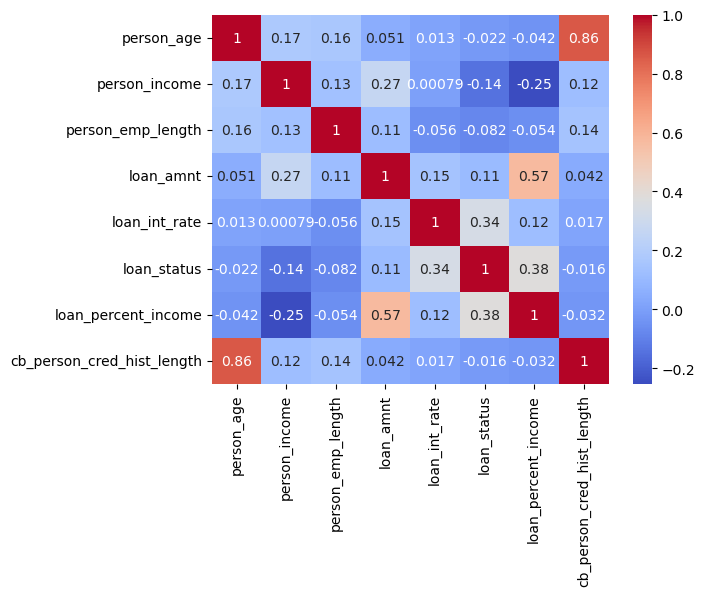

In [83]:
sns.heatmap(df.corr(numeric_only = True), annot = True, cmap = 'coolwarm')

# Data Validation and Outlier Handling

In [84]:
df_copy = df.copy()

print(f"Original rows : {df_copy.shape[0]}")

# Remove duplicate rows
df_copy.drop_duplicates(inplace = True)
print(f"Original rows : {df_copy.shape[0]}")

Original rows : 32581
Original rows : 32416


In [85]:
# Remove ages below 18 or above 100
df_copy = df_copy[df_copy['person_age'] >= 18] 
df_copy = df_copy[df_copy['person_age'] <= 100]

# Remove employment length greater than age or extreme outliers(>60)
df_copy = df_copy[df_copy['person_emp_length'] <= df_copy['person_age']]
df_copy = df_copy[df_copy['person_emp_length'] <= 60]

# Remove the rows with zero or negative income and loan amount
df_copy = df_copy[df_copy['loan_amnt'] > 0]

# Check if the interest rate looks realistic
print("Loan interest rate range from (min : 5.42 and max : 23.22)")

Loan interest rate range from (min : 5.42 and max : 23.22)


# Features, Target & Train-Test Split

In [86]:
X = df_copy.drop('loan_status', axis = 1)
y = df_copy['loan_status']

In [87]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42, stratify = y)

In [88]:
numeric_cols = ['person_age', 'person_income', 'person_emp_length', 'loan_amnt',
       'loan_int_rate', 'loan_percent_income',
       'cb_person_cred_hist_length']

categorical_cols = ['person_home_ownership', 'loan_intent', 'loan_grade',
       'cb_person_default_on_file']

# Handle Class Imbalance

In [89]:
scale_weights = (y_train == 0).sum() / (y_train == 1).sum()

In [90]:
scale_weights

np.float64(3.6312213039485766)

# Pipelines & Columns Transformer

In [91]:
# Logistic Regression : impute + scale numeric , impute + OneHot Encoding
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

preprocessor_lr = ColumnTransformer(
    transformers = [
        #Pipeline for numerical cols
        ('num', Pipeline([
            ('imputer', SimpleImputer(strategy = 'median')),
            ('scaler', StandardScaler())
        ]), numeric_cols),
        # Pipeline for categorical cols
        ('cat', Pipeline([
            ('imputer', SimpleImputer(strategy = 'constant', fill_value = "Missing")),
            ('onehot', OneHotEncoder(handle_unknown = 'ignore'))
        ]), categorical_cols)
    ]
)

# Preprocessing for xgBoost

In [92]:
# XGBoost : impute numeric only (No scaling), impute + OneHot Encoding

preprocessor_xg = ColumnTransformer(
    transformers = [
        #Pipeline for numerical cols
        ('num', Pipeline([
            ('imputer', SimpleImputer(strategy = 'median'))
        ]), numeric_cols),
        # Pipeline for categorical cols
        ('cat', Pipeline([
            ('imputer', SimpleImputer(strategy = 'constant', fill_value = "Missing")),
            ('onehot', OneHotEncoder(handle_unknown = 'ignore'))
        ]), categorical_cols)
    ]
)

# Stratified Cross Validation

In [93]:
from sklearn.model_selection import StratifiedKFold, cross_validate
cv = StratifiedKFold(n_splits = 5, shuffle = True, random_state = 42)

scoring = {'roc_auc' : 'roc_auc', 'accuracy' : 'accuracy', 'precision' : 'precision', 'recall' : 'recall', 'f1' : 'f1'}

In [94]:
# Logistic Regression 
from sklearn.linear_model import LogisticRegression
lr_cv_pipeline = Pipeline([
    ('preprocessor', preprocessor_lr),
    ('classifier', LogisticRegression(max_iter = 1000, class_weight = 'balanced', random_state = 42))
])

In [95]:
lr_cv_pipeline

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['person_age',
                                                   'person_income',
                                                   'person_emp_length',
                                                   'loan_amnt', 'loan_int_rate',
                                                   'loan_percent_income',
                                                   'cb_person_cred_hist_length']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='Missing',
                                                                                 strategy='constant')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['person_home_ownership',
                                                   'loan_intent', 'loan_grade',
                                                   'cb_person_default_on_file'])])),
                ('classifier',
                 LogisticRegression(class_weight='balanced', max_iter=1000,
                                    random_state=42))])

In [96]:
# XGBoost Model 
from xgboost import XGBClassifier
xgb_cv_pipeline = Pipeline([
    ('preprocessor', preprocessor_xg),
    ('classifier', XGBClassifier(
        n_estimators = 300, max_depth = 5, learning_rate = 0.1, 
        scale_pos_weight = scale_weights, random_state = 42
    ))
])

In [97]:
for cv_name , pipe in [("Logistic Regression", lr_cv_pipeline), ("XGBoost", xgb_cv_pipeline)]:
    cv_results = cross_validate(pipe, X_train, y_train, cv = cv, scoring = scoring, n_jobs = -1)

    print(cv_name)
    print(f"ROC-AUC : {cv_results["test_roc_auc"].mean()}")
    print(f"Accuracy : {cv_results["test_accuracy"].mean()}")
    print(f"Precision : {cv_results["test_precision"].mean()}")
    print(f"Recall : {cv_results["test_recall"].mean()}")
    print(f"F1 : {cv_results["test_f1"].mean()}")

Logistic Regression
ROC-AUC : 0.8705112830525306
Accuracy : 0.8115949542892269
Precision : 0.5448226008889892
Recall : 0.7781450872359963
F1 : 0.6408013995933108
XGBoost
ROC-AUC : 0.9471668355515135
Accuracy : 0.9182296642215565
Precision : 0.8195330117664359
Recall : 0.7974288337924702
F1 : 0.8081410985599564


# Evaluation Helper Function

In [98]:
from sklearn.metrics import accuracy_score, classification_report,  precision_score, recall_score, f1_score , confusion_matrix, precision_recall_curve

def evaluate_model(model_name, model, X_test, y_test, threshold=None):
    y_pred_prob = model.predict_proba(X_test)[:, 1]

    if threshold is not None:
        y_pred = (y_pred_prob >= threshold).astype(int)
    else:
        y_pred = model.predict(X_test)

    print(f"{model_name} Metrics:")
    print(f"Threshold : {threshold if threshold is not None else 'default (0.5)'}")
    print(f"Accuracy  : {accuracy_score(y_test, y_pred):.2f}")
    print(f"Precision : {precision_score(y_test, y_pred):.2f}")
    print(f"Recall    : {recall_score(y_test, y_pred):.2f}")
    print(f"F1        : {f1_score(y_test, y_pred):.2f}\n")
    print(classification_report(y_test, y_pred))

    sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt="d")
    plt.title(f"{model_name} Confusion Matrix")
    plt.ylabel("Actual values")
    plt.xlabel("Predicted values")
    plt.show()

    precisions, recalls, _thr = precision_recall_curve(y_test, y_pred_prob)
    plt.plot(recalls, precisions)
    plt.xlabel("Recall")
    plt.ylabel("Precision")
    plt.title(f"{model_name} Precision-Recall Curve")
    plt.show()

# Baseline Model

In [99]:
baseline_model = Pipeline([
    ('preprocessor', preprocessor_lr),
    ('classifier', LogisticRegression(class_weight="balanced"))
])

baseline_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['person_age',
                                                   'person_income',
                                                   'person_emp_length',
                                                   'loan_amnt', 'loan_int_rate',
                                                   'loan_percent_income',
                                                   'cb_person_cred_hist_length']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='Missing',
                                                                                 strategy='constant')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['person_home_ownership',
                                                   'loan_intent', 'loan_grade',
                                                   'cb_person_default_on_file'])])),
                ('classifier', LogisticRegression(class_weight='balanced'))])

In [100]:
xg_model = Pipeline([
    ('preprocessor', preprocessor_xg),
    ('classifier', XGBClassifier(learning_rate = 0.1, scale_pos_weight = scale_weights, random_state = 42))
])

xg_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['person_age',
                                                   'person_income',
                                                   'person_emp_length',
                                                   'loan_amnt', 'loan_int_rate',
                                                   'loan_percent_income',
                                                   'cb_person_cred_hist_length']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='Missing',
                                                                                 strategy='consta...
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.1,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=None, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=None, n_jobs=None,
                               num_parallel_tree=None, ...))])

# Evaluating Models

Baseline Logistic Model Metrics:
Threshold : default (0.5)
Accuracy  : 0.82
Precision : 0.56
Recall    : 0.79
F1        : 0.65

              precision    recall  f1-score   support

           0       0.93      0.83      0.88      4943
           1       0.56      0.79      0.65      1362

    accuracy                           0.82      6305
   macro avg       0.75      0.81      0.77      6305
weighted avg       0.85      0.82      0.83      6305



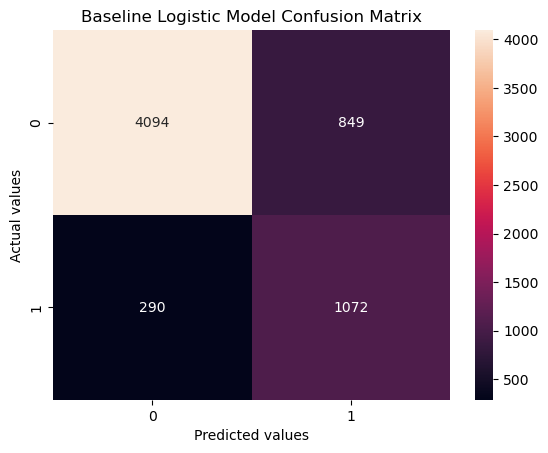

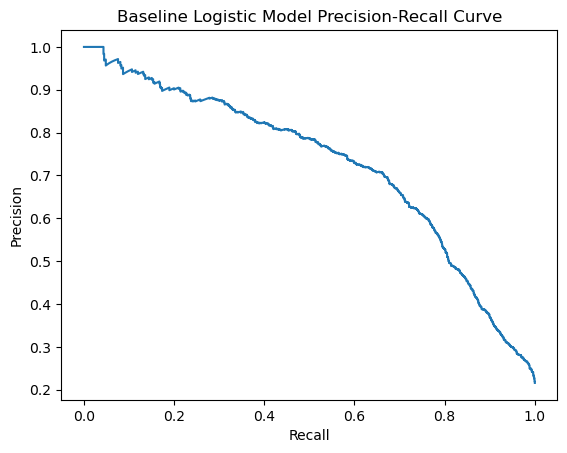

In [101]:
evaluate_model("Baseline Logistic Model", baseline_model, X_test, y_test)

XGBoost Metrics:
Threshold : default (0.5)
Accuracy  : 0.92
Precision : 0.82
Recall    : 0.79
F1        : 0.80

              precision    recall  f1-score   support

           0       0.94      0.95      0.95      4943
           1       0.82      0.79      0.80      1362

    accuracy                           0.92      6305
   macro avg       0.88      0.87      0.88      6305
weighted avg       0.92      0.92      0.92      6305



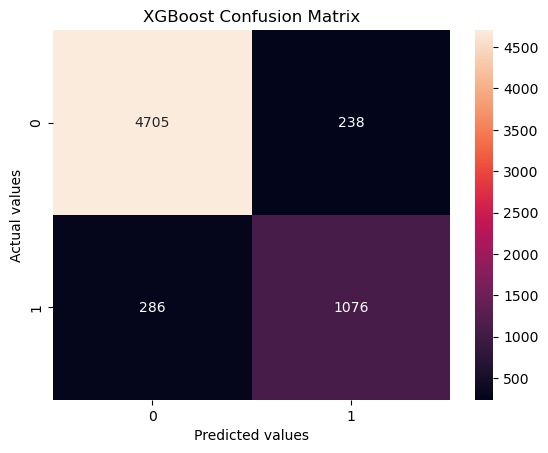

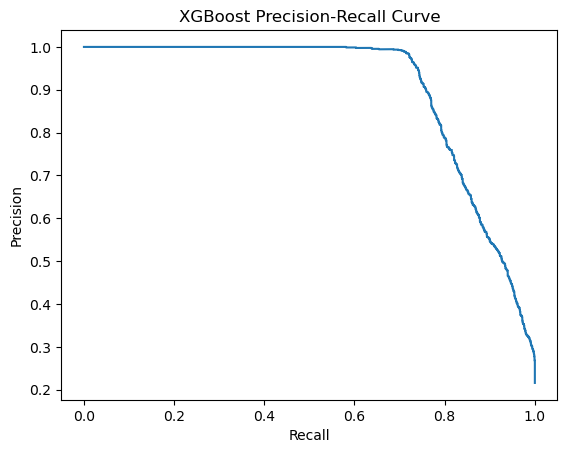

In [102]:
evaluate_model("XGBoost", xg_model, X_test, y_test)

In [103]:
from scipy.stats import uniform, randint

In [104]:
from sklearn.model_selection import RandomizedSearchCV
param_grid = {
    "classifier__n_estimators" : randint(150, 600),
    "classifier__max_depth" : randint(3, 9),
    "classifier__learning_rate" : uniform(0.01, 0.5),
    "classifier__subsample" : uniform(0.6, 0.4),
    "classifier__colsample_bytree" : uniform(0.6, 0.4),
    "classifier__min_child_weight" : randint(1, 10),
    "classifier__gamma" : uniform(0, 5)
}

In [105]:
random_search = RandomizedSearchCV(xg_model, param_grid, n_iter = 150, cv = cv, scoring="average_precision", n_jobs = -1, verbose = 1)

In [106]:
random_search.fit(X_train, y_train)

Fitting 5 folds for each of 150 candidates, totalling 750 fits


RandomizedSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
                   estimator=Pipeline(steps=[('preprocessor',
                                              ColumnTransformer(transformers=[('num',
                                                                               Pipeline(steps=[('imputer',
                                                                                                SimpleImputer(strategy='median'))]),
                                                                               ['person_age',
                                                                                'person_income',
                                                                                'person_emp_length',
                                                                                'loan_amnt',
                                                                                'loan_int_rate',
                                                                                'loan_percent_income',
                                                                                'cb_person_cred_hist_length...
                                        'classifier__min_child_weight': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x0000024AC2832570>,
                                        'classifier__n_estimators': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x0000024AA9E45CD0>,
                                        'classifier__subsample': <scipy.stats._distn_infrastructure.rv_continuous_frozen object at 0x0000024AAFFBC710>},
                   scoring='average_precision', verbose=1)

In [107]:
print(f"Score after performing tuning : {random_search.best_score_ : .2f}")

Score after performing tuning :  0.90


In [108]:
random_search.best_params_

{'classifier__colsample_bytree': np.float64(0.9446635434366418),
 'classifier__gamma': np.float64(0.13510466029277746),
 'classifier__learning_rate': np.float64(0.02976028813523384),
 'classifier__max_depth': 7,
 'classifier__min_child_weight': 2,
 'classifier__n_estimators': 598,
 'classifier__subsample': np.float64(0.6813604853199212)}

# Compare Both Models Side by Side

Logistic Regression Metrics:
Threshold : default (0.5)
Accuracy  : 0.82
Precision : 0.56
Recall    : 0.79
F1        : 0.65

              precision    recall  f1-score   support

           0       0.93      0.83      0.88      4943
           1       0.56      0.79      0.65      1362

    accuracy                           0.82      6305
   macro avg       0.75      0.81      0.77      6305
weighted avg       0.85      0.82      0.83      6305



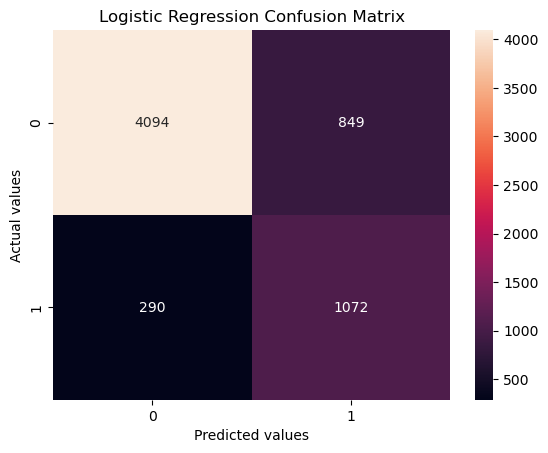

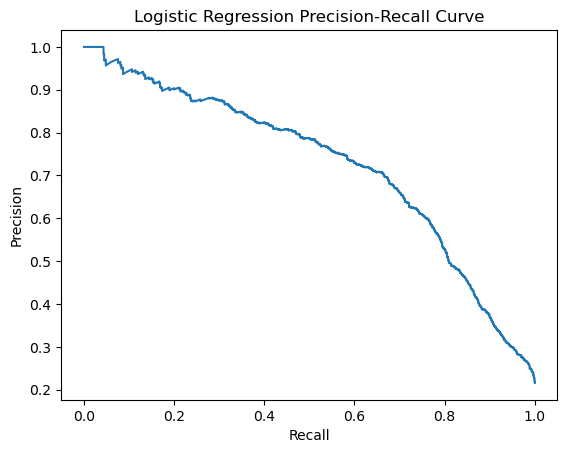

In [109]:
evaluate_model("Logistic Regression", baseline_model, X_test, y_test)

XGBoost Metrics:
Threshold : default (0.5)
Accuracy  : 0.93
Precision : 0.85
Recall    : 0.79
F1        : 0.82

              precision    recall  f1-score   support

           0       0.94      0.96      0.95      4943
           1       0.85      0.79      0.82      1362

    accuracy                           0.93      6305
   macro avg       0.90      0.88      0.89      6305
weighted avg       0.92      0.93      0.92      6305



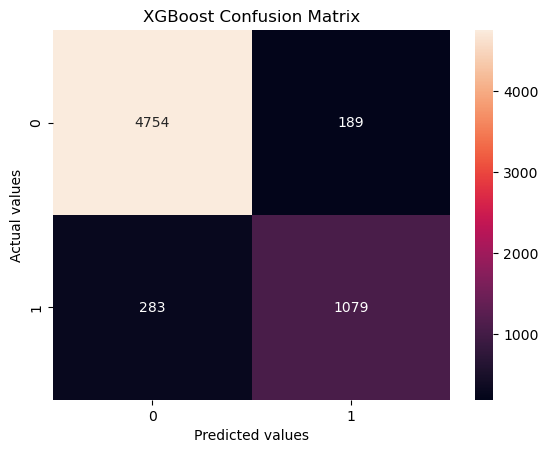

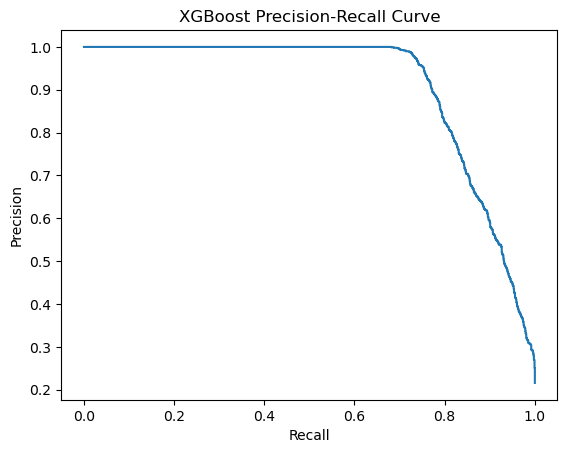

In [110]:
evaluate_model("XGBoost", random_search, X_test, y_test)

# Optimizing the Classification Threshold

XGBoost Metrics:
Threshold : 0.6907042264938354
Accuracy  : 0.94
Precision : 0.95
Recall    : 0.74
F1        : 0.83

              precision    recall  f1-score   support

           0       0.93      0.99      0.96      4943
           1       0.95      0.74      0.83      1362

    accuracy                           0.94      6305
   macro avg       0.94      0.87      0.90      6305
weighted avg       0.94      0.94      0.93      6305



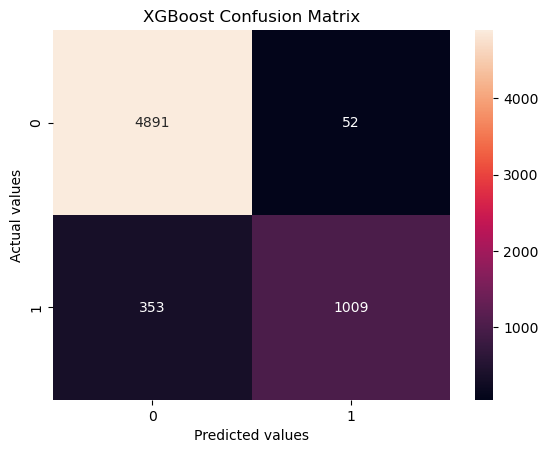

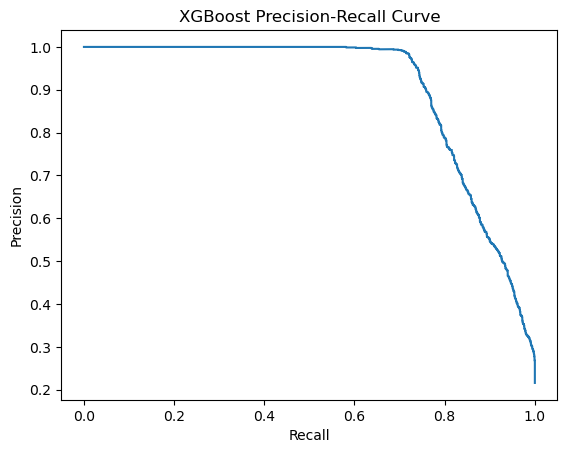

In [ ]:
# Get the probability of class 1 from XGBoost
prob = xg_model.predict_proba(X_test)[:, 1]

# For each threshold calculate Precision and Recall
precision, recall, thresholds = precision_recall_curve(y_test, prob)

# Calculate F1 score for each threshold
f1 = 2 * (precision * recall) / (precision + recall + 1e-9)

# Get the threshold that produces the highest f1-score
best = np.argmax(f1[:-1])
best_threshold = thresholds[best]

# Evaluate the XGBoost model using that threshold
evaluate_model("XGBoost", xg_model, X_test, y_test, best_threshold)

# Probability Calibration

In [133]:
# 1. Calibrated XGBoost Model
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
best_model = random_search.best_estimator_
calibrated_model = CalibratedClassifierCV(
    best_model, method = "sigmoid", cv = 5
)

calibrated_model.fit(X_train, y_train)

CalibratedClassifierCV(cv=5,
                       estimator=Pipeline(steps=[('preprocessor',
                                                  ColumnTransformer(transformers=[('num',
                                                                                   Pipeline(steps=[('imputer',
                                                                                                    SimpleImputer(strategy='median'))]),
                                                                                   ['person_age',
                                                                                    'person_income',
                                                                                    'person_emp_length',
                                                                                    'loan_amnt',
                                                                                    'loan_int_rate',
                                                                                    'loan_percent_income',
                                                                                    'cb_person_cred_hist_length']),
                                                                                  ('cat',
                                                                                   Pipeline(steps=[('imputer',
                                                                                                    SimpleImputer...
                                                                grow_policy=None,
                                                                importance_type=None,
                                                                interaction_constraints=None,
                                                                learning_rate=np.float64(0.02976028813523384),
                                                                max_bin=None,
                                                                max_cat_threshold=None,
                                                                max_cat_to_onehot=None,
                                                                max_delta_step=None,
                                                                max_depth=7,
                                                                max_leaves=None,
                                                                min_child_weight=2,
                                                                missing=nan,
                                                                monotone_constraints=None,
                                                                multi_strategy=None,
                                                                n_estimators=598,
                                                                n_jobs=None,
                                                                num_parallel_tree=None, ...))]))

In [134]:
# 2. Get Probabilities
uncalibrated = xg_model.predict_proba(X_test)[:,1]
calibrated = calibrated_model.predict_proba(X_test)[:,1]

In [135]:
calibrated

array([0.65237818, 0.03627416, 0.95395573, ..., 0.40954888, 0.02059162,
       0.01655288])

In [136]:
uncalibrated

array([0.84068304, 0.15292269, 0.9841339 , ..., 0.4585313 , 0.09387756,
       0.05197704], dtype=float32)

In [137]:
# 3. Create Calibration curves
actual_uncal, predicted_uncal = calibration_curve(y_test, uncalibrated, n_bins = 10)

In [138]:
actual_cal, predicted_cal = calibration_curve(y_test, calibrated, n_bins = 10)

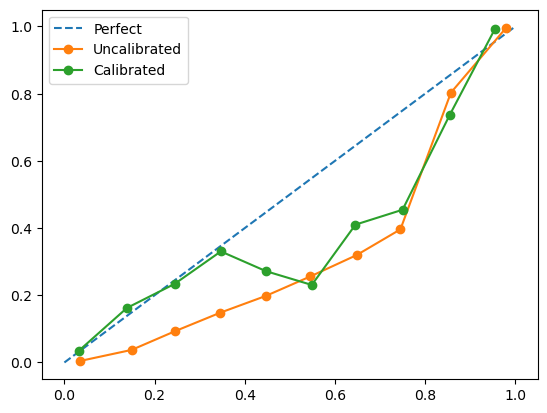

In [139]:
# 4. Plot
plt.plot([0,1], [0, 1], '--', label = "Perfect")
plt.plot(predicted_uncal, actual_uncal, "o-", label = "Uncalibrated")
plt.plot(predicted_cal, actual_cal, "o-", label = "Calibrated")
plt.legend()

# SHAP Interpretation - Global & Local

1. SHAP tells you why a model make a particular predictions
2. SHAP can tell you how each feature contributed
3. SHAP tells which features push the predictions up or down and how much?

In [140]:
# Install the SHAP

!pip install shap
import shap

In [141]:
# Get the trained XGBoost classifier model out of the pipeline

xgb_classifier = xg_model.named_steps['classifier']
xgb_classifier

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.1, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=None,
              n_jobs=None, num_parallel_tree=None, ...)

In [142]:
# Transform X_test using the same preprocessing used for training

X_test_transformed = xg_model.named_steps['preprocessor'].transform(X_test)

In [143]:
# Get feature names after one-hot encoding, so plots are readable

feature_names = xg_model.named_steps['preprocessor'].get_feature_names_out()

In [144]:
# Convert to a dataframe for cleaner SHAP plots

X_test_df = pd.DataFrame(X_test_transformed, columns = feature_names)

In [145]:
X_test_df

,num__person_age,num__person_income,num__person_emp_length,num__loan_amnt,num__loan_int_rate,num__loan_percent_income,num__cb_person_cred_hist_length,cat__person_home_ownership_MORTGAGE,cat__person_home_ownership_OTHER,cat__person_home_ownership_OWN,...,cat__loan_intent_VENTURE,cat__loan_grade_A,cat__loan_grade_B,cat__loan_grade_C,cat__loan_grade_D,cat__loan_grade_E,cat__loan_grade_F,cat__loan_grade_G,cat__cb_person_default_on_file_N,cat__cb_person_default_on_file_Y
0,24.0,30000.0,1.0,15000.0,15.68,0.50,3.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
1,23.0,60000.0,6.0,25600.0,10.99,0.43,4.0,1.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
2,29.0,18000.0,2.0,3600.0,15.27,0.20,6.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
3,32.0,130000.0,7.0,13000.0,12.69,0.10,8.0,1.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
4,23.0,45288.0,7.0,20500.0,9.25,0.45,2.0,1.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6300,21.0,75000.0,5.0,20000.0,13.11,0.27,2.0,1.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
6301,29.0,265000.0,2.0,25000.0,11.26,0.09,10.0,1.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
6302,25.0,48996.0,8.0,5000.0,9.88,0.10,2.0,1.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
6303,27.0,115000.0,11.0,8000.0,7.51,0.07,7.0,1.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


In [146]:
# Create SHAP explainer built for tree-based model
explainer = shap.TreeExplainer(xgb_classifier)

In [147]:
# Calculate SHAP values for every row in the test set
shap_values = explainer.shap_values(X_test_df)
shap_values

array([[-1.12646714e-01, -1.26755506e-01,  1.33791879e-01, ...,
        -5.45465993e-03, -2.11942941e-03,  0.00000000e+00],
       [-4.48196474e-03, -9.36791718e-01, -1.31195694e-01, ...,
        -7.36764725e-03, -7.80719239e-03,  0.00000000e+00],
       [ 9.69848782e-02,  3.64243174e+00,  1.15845121e-01, ...,
        -6.26665959e-03, -1.36033131e-03,  0.00000000e+00],
       ...,
       [ 1.35269035e-02,  5.85532665e-01,  8.45345184e-02, ...,
        -8.13906733e-03, -5.82884718e-03,  0.00000000e+00],
       [ 4.71081920e-02, -8.11781585e-01,  7.55942017e-02, ...,
        -9.23685916e-03, -7.67303910e-03,  0.00000000e+00],
       [-1.55267730e-01, -6.46857083e-01,  2.11317744e-02, ...,
        -8.27899296e-03, -5.55641949e-03,  0.00000000e+00]], dtype=float32)

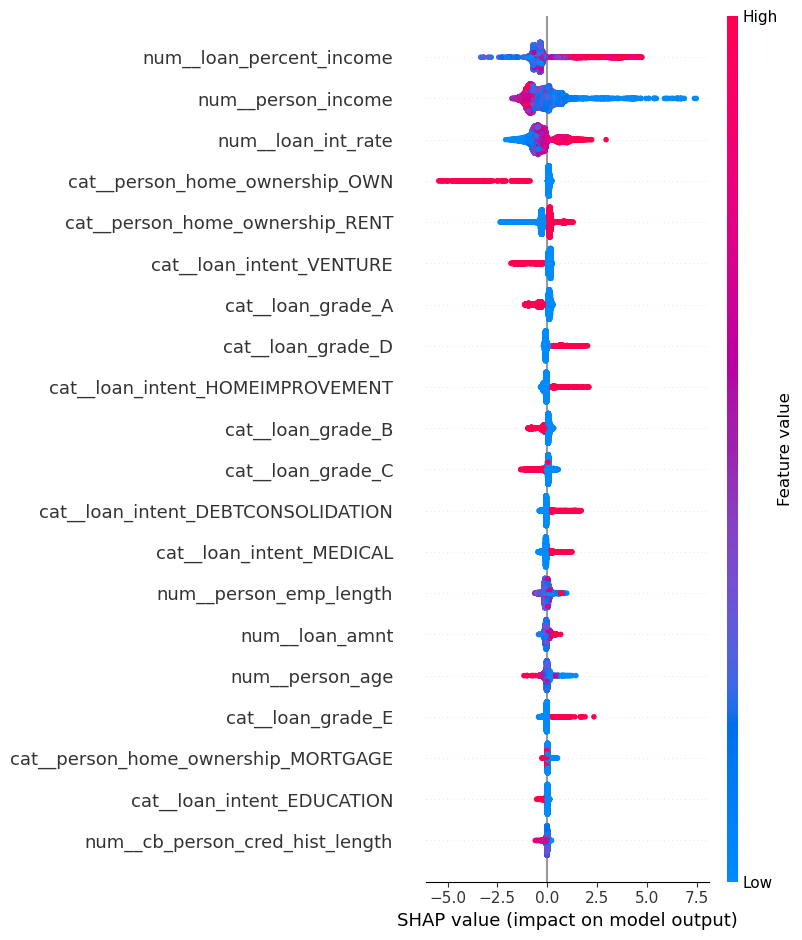

In [148]:
shap.summary_plot(shap_values, X_test_df)

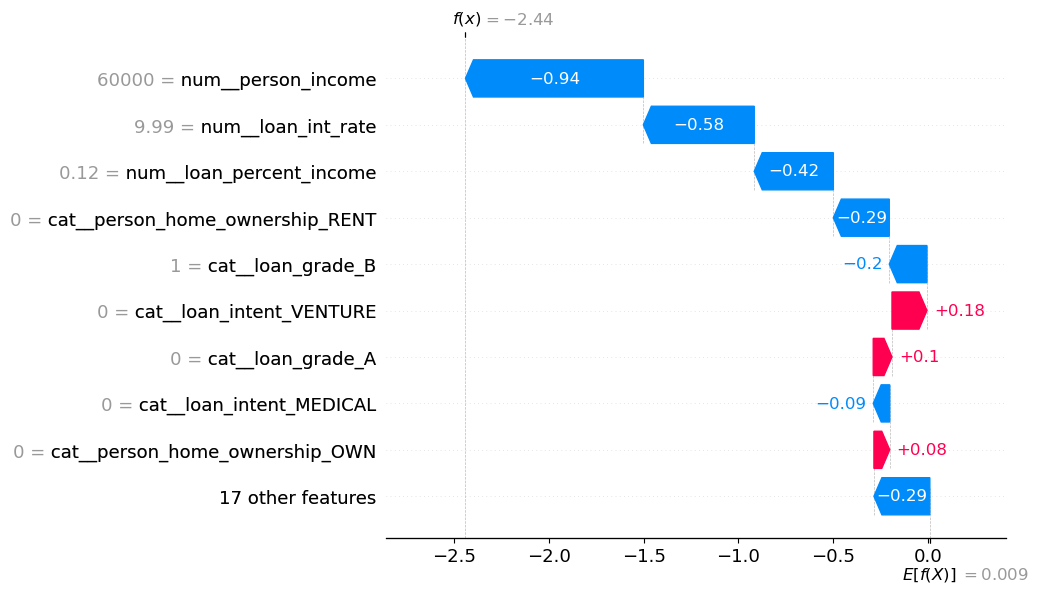

In [149]:
# 1. Pick one row to explain, eg : the 5th applicant in the test set
row_index = 5

# 2. Draw a waterfall plot showing how each feature pushed the prediction up or down
shap.plots.waterfall(
    shap.Explanation(
        values = shap_values[row_index],
        base_values = explainer.expected_value,
        data = X_test_df.iloc[row_index],
        feature_names = feature_names
    )
)

# Analyzing False Positives and False Negatives

In [150]:
# Get Predictions from the best performing XGBoostModel on the test set
y_pred = random_search.predict(X_test)

In [151]:
# Create a DataFrame to easily compare the actual and predicted values
result_df = X_test.copy()
result_df['actual'] = y_test
result_df['predicted'] = y_pred
result_df

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length,actual,predicted
14455,24,30000,OWN,1.0,MEDICAL,E,15000,15.68,0.50,N,3,1,1
8701,23,60000,MORTGAGE,6.0,EDUCATION,C,25600,NaN,0.43,N,4,0,0
19804,29,18000,RENT,2.0,EDUCATION,C,3600,15.27,0.20,N,6,1,1
27252,32,130000,MORTGAGE,7.0,MEDICAL,B,13000,12.69,0.10,N,8,0,0
5610,23,45288,MORTGAGE,7.0,DEBTCONSOLIDATION,B,20500,9.25,0.45,N,2,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
11661,21,75000,MORTGAGE,5.0,PERSONAL,C,20000,13.11,0.27,Y,2,0,0
27837,29,265000,MORTGAGE,2.0,PERSONAL,B,25000,11.26,0.09,N,10,0,0
17192,25,48996,MORTGAGE,8.0,MEDICAL,B,5000,9.88,0.10,N,2,1,1
26858,27,115000,MORTGAGE,11.0,MEDICAL,A,8000,7.51,0.07,N,7,0,0


In [152]:
# Identify False Positives : Model Predicted 1 but the actual was 0
false_positive = result_df[(result_df['actual'] == 0) & (result_df['predicted'] == 1)]

# Identify False Negatives : Model predicted 0 but the actual was 1
false_negative = result_df[(result_df['actual'] == 1) & (result_df['predicted'] == 0)]

In [153]:
print(f"False Positives : {len(false_positive)}")
print(f"False Negatives : {len(false_negative)}")

False Positives : 189
False Negatives : 283


False Negative > False Positive

# Save the Final Model

In [154]:
import joblib

joblib.dump(calibrated_model, 'credit_risk_model.pkl')

['credit_risk_model.pkl']

In [159]:
import numpy as np
calibrated_proba = calibrated_model.predict_proba(X_test)[:, 1]

# For each threshold calculate Precision and Recall
precision, recall, thresholds = precision_recall_curve(y_test, calibrated_proba)

# Calculate F1 score for each threshold
f1_scores = 2 * (precision * recall) / (precision + recall + 1e-9)

# Get the threshold that produces the highest f1-score
best = np.argmax(f1[:-1])
best_threshold = thresholds[np.argmax(f1_scores[:-1])]
print("New threshold : ", best_threshold)

New threshold :  0.7702730315289454


In [160]:
joblib.dump(best_threshold, 'best_threshold.pkl')

['best_threshold.pkl']